# Collections performance audit: is "+11% MoM recovery" real, and where should ₹10 Cr go?

**Business question.** The business reports *"Recovery has improved by 11% month-on-month."* Leadership doubts it. This notebook answers four questions: (1) what happened, (2) why, (3) whether the 11% is real, and (4) where ₹10 Cr should go.

**Evidence labels used throughout**

| Label | Meaning |
|---|---|
| **FACT** | Directly observable in the data; no model needed |
| **STRONG EVIDENCE** | A statistical test with a clear result that survives reasonable alternative specifications |
| **CORRELATION** | An association; causal direction not established |
| **HYPOTHESIS** | A plausible explanation the data cannot confirm |
| **ASSUMPTION** | An input we chose (often external, e.g. unit costs); it is listed in `docs/assumptions_register.md` |

**Where the work happens.** Cleaning and modelling run in SQL (`sql/00_raw.sql` → `sql/70_dq_checks.sql`, executed by `run_pipeline.py`). This notebook reads the resulting DuckDB file and does the statistics. Section numbers match `docs/`.

In [1]:
import pathlib, subprocess, sys, warnings, duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf, statsmodels.api as sm, scipy.stats as st
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
DB = ROOT/'outputs'/'collections.duckdb'
if not DB.exists():
    subprocess.run([sys.executable, str(ROOT/'run_pipeline.py')], check=True)
con = duckdb.connect(str(DB), read_only=True)
Q = lambda s: con.execute(s).df()
CH = ROOT/'outputs'/'charts'; CH.mkdir(parents=True, exist_ok=True)
MARTS = ROOT/'outputs'/'tableau'; MARTS.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
BLUE, GRAY, RED, ORANGE, INK, INK2 = '#2a78d6', '#8a8984', '#e34948', '#eb6834', '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.dpi':130, 'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.edgecolor':'#c9c8c3', 'axes.labelcolor':INK2, 'xtick.color':INK2, 'ytick.color':INK2,
                     'axes.titleweight':'bold', 'axes.titlesize':11, 'font.size':9, 'axes.grid':True,
                     'grid.color':'#ecebe7', 'grid.linewidth':0.6})
cr = lambda x: x/1e7   # ₹ -> crore

## 1. What data do we actually have?
The brief promises roughly 12 months of data. We verify that before analysing anything.

In [2]:
display(Q('select * from val.inventory'))
display(Q('select tbl, n_rows, n_pk, duplicate_pk_rows, first_ts, last_ts, span_days from val.table_profile'))
mc = Q("select * from val.month_completeness where tbl='payments'"); display(mc)

,table_name,delivered
0,account_status_history,True
1,accounts,True
2,agent_sessions,True
3,agents,True
4,borrowers,True
5,call_attempts,True
6,call_dispositions,True
7,calls,True
8,campaigns,True
9,complaints,True


,tbl,n_rows,n_pk,duplicate_pk_rows,first_ts,last_ts,span_days
0,payments,25500,25000,500,2026-01-01 00:14:40,2026-08-08 23:50:23,220
1,calls,91350,90000,1350,2025-12-29 08:22:37,2026-08-12 15:43:05,227
2,call_attempts,120000,120000,0,2026-01-01 00:01:18,2026-08-08 23:58:40,220
3,call_dispositions,35000,35000,0,2026-01-01 00:10:00,2026-08-08 23:50:50,220
4,whatsapp_events,60600,60000,600,2026-01-01 00:01:49,2026-08-08 23:56:16,220
5,sms_events,45000,45000,0,2026-01-01 00:04:16,2026-08-08 23:46:06,220
6,field_visits,25000,25000,0,2026-01-01 00:07:53,2026-08-08 23:50:03,220
7,promises_to_pay,18000,18000,0,2026-01-01 00:24:14,2026-08-08 23:59:33,220
8,complaints,8000,8000,0,2026-01-01 00:38:02,2026-08-08 23:35:33,220
9,account_status_history,60000,60000,0,2026-01-01 00:01:08,2026-08-08 23:50:45,220


,tbl,month_start,calendar_days,days_with_events,is_complete
0,payments,2026-01-01,31,31,True
1,payments,2026-02-01,28,28,True
2,payments,2026-03-01,31,31,True
3,payments,2026-04-01,30,30,True
4,payments,2026-05-01,31,31,True
5,payments,2026-06-01,30,30,True
6,payments,2026-07-01,31,31,True
7,payments,2026-08-01,31,8,False


**FACT: coverage.**
* All **17** expected tables were delivered.
* Event data runs from **1 Jan to 8 Aug 2026** (220 days): **7 complete months (Jan–Jul)** plus 8 days of August, with no missing days in between. The brief's "≈12 months" does not exist in the files, so every result here refers to Jan–Jul 2026.
* August is excluded from all month-on-month comparisons.

**FACT: dimensions that are absent** (flagged as gaps, not analysed):
* client
* language
* dialer mode (human / predictive / IVR / agentic voice)
* any cost or tariff field

So *cost per ₹ recovered* cannot be measured. §8 replaces it with a *break-even cost per touch* that Finance can check.

Full detail is in `docs/01_data_validation.md`.

## 2. Golden dataset: Raw → Rejected/Corrected → Golden

In [3]:
display(pd.read_csv(ROOT/'outputs'/'cleaning_waterfall.csv'))
display(pd.read_csv(ROOT/'outputs'/'rejection_log.csv'))
money = Q('''select sum(amount)/1e7 all_rows_with_dups,
                    (select sum(amount) from cln.payments)/1e7 after_dedup,
                    (select sum(net_amount) from gld.fct_payment)/1e7 golden_success,
                    sum(amount) filter (where payment_status='SUCCESS')/1e7 reported_style_success_with_dups
             from stg.payments''').T.round(2)
money.columns=['₹ Cr']; display(money)
print('Duplicate payment_id groups, classified by evidence:'); display(Q('select * from fx.a_duplicate_payment_classes').round(0))
print('Other duplicate / retry patterns searched for:'); display(Q('select * from fx.a_retry_patterns'))
ref_loss = Q('''select sum(net_amount) filter (where rn>1)/1e7 from (select net_amount, row_number() over (partition by payment_reference order by _src_row) rn
               from cln.payments where is_recognised and payment_reference is not null)''').iloc[0,0]
print(f'SUCCESS cash that a dedup on payment_reference would wrongly delete: ₹{ref_loss:.1f} Cr')

,entity,raw_rows,clean_rows,golden_rows
0,payments,25500,25000,17534
1,calls,91350,90000,82907
2,call_attempts,120000,120000,120000
3,call_dispositions,35000,35000,35000
4,whatsapp_events,60600,60000,59999
5,sms_events,45000,45000,44998
6,field_visits,25000,25000,25000
7,promises_to_pay,18000,18000,18000
8,borrowers,30600,11015,11015
9,agents,30000,30000,1000


,table_name,rule_id,rule,action,rows_affected,amount_inr
0,payments,R-PAY-1a,"duplicate payment_id, every column identical",1 copy removed per group,486,2.501146e+07
1,payments,R-PAY-1b,"duplicate payment_id, identical except referen...",reference-less copy removed,14,8.904995e+05
2,payments,R-PAY-1c,duplicate payment_id groups that are NOT prova...,"none found (would be quarantined, not deleted)",0,NaN
3,payments,R-PAY-2,payment_reference reused across different acco...,kept + flagged,7218,NaN
4,payments,R-PAY-3,status not SUCCESS (FAILED/PENDING/REVERSED),excluded from recovery,7466,5.633083e+08
5,payments,R-PAY-4,missing payment_reference,kept + flagged,368,1.887395e+07
6,calls,R-CALL-1,duplicate call_id rows,"removed (kept agent-bearing, earliest copy)",1350,NaN
7,calls,R-CALL-2,duplicate call_id with timestamps 1-5 days apart,"earliest kept, flagged",11,NaN
8,calls,R-CALL-3,missing agent_id,kept; excluded from agent metrics,1759,NaN
9,calls,R-CALL-4,timestamp re-based from UTC/Dubai to IST,corrected,59962,NaN


,₹ Cr
all_rows_with_dups,191.73
after_dedup,187.89
golden_success,131.56
reported_style_success_with_dups,134.15


Duplicate payment_id groups, classified by evidence:


,duplicate_class,payment_status,groups,extra_rows,extra_amount_inr,all_provably_same_payment,min_row_of_second_copy,max_row_of_second_copy
0,IDENTICAL,FAILED,66,66.0,5060990.0,True,25008,25495
1,IDENTICAL,PENDING,56,56.0,4502633.0,True,25001,25494
2,IDENTICAL,REVERSED,29,29.0,2723935.0,True,25005,25498
3,IDENTICAL,SUCCESS,335,335.0,25011462.0,True,25002,25500
4,REFERENCE_DROPPED,FAILED,1,1.0,26769.0,True,25166,25166
5,REFERENCE_DROPPED,PENDING,1,1.0,142141.0,True,25183,25183
6,REFERENCE_DROPPED,REVERSED,1,1.0,7915.0,True,25138,25138
7,REFERENCE_DROPPED,SUCCESS,11,11.0,890500.0,True,25044,25438


Other duplicate / retry patterns searched for:


,pattern,n
0,"same account + same amount, different payment_id",0
1,"same account + same reference, different payme...",0
2,two payments on one account within 10 minutes,0
3,FAILED then SUCCESS on same account within 24h...,8
4,shared payment_reference groups with a matchin...,0


SUCCESS cash that a dedup on payment_reference would wrongly delete: ₹14.7 Cr


**What the cleaning changes in money (FACT):**
* **Duplicates, examined before deleting.** 500 `payment_id`s appear twice. In every group the two rows agree on account, amount, timestamp to the second, status, method and provider, and the second copy always sits in the last 500 rows of the file (an appended block, i.e. a re-ingestion).
  * **486 groups** are identical in every column.
  * **14 groups** are identical except that one copy has lost its `payment_reference`. The surviving row is the one that still has the reference.
  * **0 groups** are ambiguous (different amounts, times, statuses or two different references). Any such group would be quarantined, not deleted; a blocking check enforces this.
  * **Money:** 346 of the 500 are SUCCESS rows, so ₹2.59 Cr would be counted twice (₹2.50 Cr identical + ₹0.09 Cr reference-dropped), which is 1.9% of reported cash. The other 154 duplicates are FAILED, PENDING or REVERSED and carry no cash.
* **No other inflation pattern exists.** No account has two payments of the same amount, none has two payments within 10 minutes, and no reference is reused on the same account. Eight FAILED→SUCCESS pairs within 24 hours look like genuine retries; both rows are correct as recorded.
* **Non-cash rows.** 7,466 rows are FAILED, PENDING or REVERSED. They are attempts, not cash, so they are excluded from recovery.
* **`payment_reference` is not a duplicate key.** 7,218 payments share a reference with a *different* account, amount and time. Deduplicating on it would delete ₹14.7 Cr of real cash. The column that looks cleanest is the wrong key.
* **One payment, one promise.** In v2, a payment that falls inside the window of two promises-to-pay counts toward only one of them. This affects 14 payments.

## 3. Data forensics (Part 2, A–G)

In [4]:
for t in ['a_duplicate_payments','k_late_arrival','l_paid_vs_outstanding','m_cash_by_snapshot_status','b_attribution','c_timezone_calls','c_payment_clock_sensitivity','e_agent_identity',
          'f_portfolio_vintage','g_denominator','h_ptp_integrity','i_campaign_integrity','i_calls_outside_campaign_window']:
    print('\n###', t); display(Q(f'select * from fx.{t}'))
display(Q('select * from val.fk_health'))
# D: did any telephony vendor's call-status mix shift between months? (a code-mapping change would show here)
vm = Q('''select vendor_id, strftime(event_at_ist,'%Y-%m') m, call_status from cln.calls
          where event_at_ist >= '2026-01-01' and event_at_ist < '2026-08-01' ''')
ps = pd.Series({v: st.chi2_contingency(pd.crosstab(g.m, g.call_status))[1] for v, g in vm.groupby('vendor_id')})
print(f'Vendor x month call-status mix: min p = {ps.min():.3f}; vendors with p<0.01: {(ps<0.01).sum()} of {len(ps)}; Bonferroni threshold = {0.05/len(ps):.4f}')


### a_duplicate_payments


,month_start,duplicated_ids,extra_rows,inflated_success_inr
0,2026-01-01,75,75.0,3904156.83
1,2026-02-01,67,67.0,3954834.20
2,2026-03-01,73,73.0,4321010.27
3,2026-04-01,70,70.0,3288973.64
4,2026-05-01,67,67.0,2797865.84
5,2026-06-01,58,58.0,3164766.49
6,2026-07-01,62,62.0,3036581.80
7,2026-08-01,28,28.0,1433772.62



### k_late_arrival


,metric,val
0,account_status_history: recorded_at - event_at...,-24.0
1,account_status_history: recorded_at - event_at...,24.0
2,account_status_history: rows recorded >24h aft...,0.0
3,calls: duplicate call_ids whose copies are dat...,11.0
4,calls: events dated outside the common window ...,52.0
5,payments: ingestion timestamp available (0 = n...,0.0



### l_paid_vs_outstanding


,paying_accounts,accounts_paid_more_than_outstanding,excess_inr,total_paid_inr,payers_with_outstanding_gt_principal
0,13284,1859,1.303031e+08,1.315584e+09,5794


... (18 outputs left out)


### i_calls_outside_campaign_window


,calls,outside_window,pct_outside
0,90000,72584,80.648889


,fk,n,orphans
0,payments.account_id -> accounts,25500,0
1,calls.account_id -> accounts,91350,0
2,promises_to_pay.account_id -> accounts,18000,0
3,calls.agent_id -> agents,89523,0
4,calls.campaign_id -> campaigns,91350,0
5,calls.vendor_id -> vendor_telephony,91350,0
6,accounts.borrower_id -> borrowers,30000,2913
7,call_attempts.call_id -> calls,120000,0
8,"call_attempts (call_id, account_id) -> calls",120000,119992
9,"call_dispositions (call_id, account_id) -> calls",35000,35000


Vendor x month call-status mix: min p = 0.011; vendors with p<0.01: 0 of 15; Bonferroni threshold = 0.0033


| # | Test | Found? | Evidence | Label |
|---|---|---|---|---|
| A | Duplicate payments | **Yes** | 500 `payment_id`s recorded twice (486 identical, 14 identical bar a dropped reference, 0 ambiguous); ₹2.59 Cr of SUCCESS cash, ₹28–43 lakh per month, spread evenly | FACT |
| B | Attribution errors | **Yes** | Crediting the latest call on the account picks a call made **after** the payment for 69% of payments. 80% of payments had **no touch in the 7 days before** | FACT |
| C | Timezone problems | **Yes (calls); unknowable (payments)** | 67% of calls are stored in UTC or Dubai time: all of them land in the wrong hour and 8,791 on the wrong day. Payments carry no timezone; switching their clock assumption moves any complete month by < 0.7% | FACT |
| D | Vendor / disposition code changes | **Yes, but constant over time** | `PTP` and `PROMISE_TO_PAY` co-exist across versions legacy/v1/v2, but every month has the same mix. Per-vendor call-status mix by month: no vendor below p = 0.01 (min p = 0.011 across 15 vendors; the multiple-test threshold is 0.003). No step change | FACT / STRONG EVIDENCE |
| E | Agent identity | **Yes, severe** | Each `agent_id` has ~30 overwritten master records with up to 10 names; each `employee_code` maps to ~27 agent_ids. Identities cannot be merged | FACT |
| F | Portfolio mix change | **No** | No account was opened after Nov 2025; product and DPD mix are fixed. (Limitation: DPD history doesn't exist, so DPD drift can't be measured) | FACT |
| G | Denominator manipulation | **Possible; business formula unknown** | *If* a recovery rate uses accounts not marked CLOSED/PAID/WRITEOFF as its base, it rises 1.79% → 2.73% (Jan→Jul) while the fixed-book rate stays flat. Those accounts keep paying (35% of July cash). Part of the rise is mechanical, because no status history exists before January. We **do not know** the business uses this base; this is a risk demonstration | FACT (mechanism) / HYPOTHESIS (that it is in use) |
| H | Late-arriving / re-dated events | **Partly measurable** | Status history is recorded within ±24 h of the event in both directions (clock skew, not lateness). 11 duplicate calls carry dates whole days apart. Payments have **no** ingestion timestamp, so late payments cannot be detected | FACT |
| I | Historical changes | **Yes** | Agent and borrower masters are overwritten (≈30 and up to 11 versions); account snapshot status disagrees with the latest status history for 86% of accounts; cash arrives equally from ACTIVE, CLOSED, PAID and WRITEOFF accounts (25% each), so the status field carries no information | FACT |
| J | Balance field | **Ambiguous** | 1,859 paying accounts paid more than their `outstanding_amount` (₹13.0 Cr above balance). The snapshot has no as-of date, so we cannot tell whether it is a pre- or post-payment balance | FACT (numbers) / HYPOTHESIS (cause) |
| + | PTP "KEPT" labels | **Unreliable** | Of due PTPs labelled KEPT, 4.2% have matching cash; of those labelled BROKEN, 3.4%. 394 were marked KEPT before they were due | FACT |
| + | Campaign definitions | **Inconsistent** | 46% of "DPD≥60" targets are actually ≥60 DPD; 28% of "NPA" targets are 90+; 81% of calls fall outside their campaign's dates | FACT |
| + | Cross-table keys | **Broken** | attempts and dispositions sit on a *different* account from the call they reference (>99.9%) | FACT |

## 4. Is the +11% real?
### 4.1 Reconstructing the reported number
The business did not supply its formula, so we test which plausible definition and which month pair reproduce 11%.

In [5]:
f0 = Q('select * from fx.f0_reported_mom where month_start < date \'2026-08-01\'')
cands = f0.melt(id_vars='month_start', value_vars=[c for c in f0.columns if c.startswith('mom_')], var_name='definition', value_name='mom_pct').dropna()
cands['abs_gap_to_11'] = (cands.mom_pct-11).abs()
display(cands.sort_values('abs_gap_to_11').head(6).round(2))

,month_start,definition,mom_pct,abs_gap_to_11
2,2026-03-01,mom_success_with_dups_pct,10.99,0.01
23,2026-03-01,mom_success_count_pct,11.27,0.27
16,2026-03-01,mom_success_plus_pending_pct,10.64,0.36
9,2026-03-01,mom_all_rows_pct,12.23,1.23
6,2026-07-01,mom_success_with_dups_pct,6.46,4.54
13,2026-07-01,mom_all_rows_pct,5.92,5.08


**STRONG EVIDENCE (reconstruction, not a disclosed formula).** Only one combination comes within 0.5 pp of 11%: the sum of `amount` where `status='SUCCESS'`, **duplicates included**, **calendar month**, **March vs February 2026**, which gives **+10.99%**. The next closest candidates (count of payments +11.3%, success + pending +10.6%) are the *same month pair*. Whatever the exact formula, the claim compares March with February.

March has 31 days and February 28. 31/28 − 1 = **+10.7%**.

In [6]:
k = Q('select * from mart.kpi_monthly where is_complete order by month_start')
daily = Q('select * from mart.kpi_daily where day_ist < date \'2026-08-01\'')
daily['day_ist']=pd.to_datetime(daily.day_ist); daily['m']=daily.day_ist.dt.to_period('M').astype(str)
feb, mar = k.iloc[1], k.iloc[2]
rep    = 100*(mar.reported_collections/feb.reported_collections-1)
dedup  = 100*(mar.net_collections/feb.net_collections-1)
perday = 100*(mar.net_collections_per_day/feb.net_collections_per_day-1)
rng=np.random.default_rng(42)
fa, ma = daily.query("m=='2026-02'").net_collections.values, daily.query("m=='2026-03'").net_collections.values
bs=[rng.choice(ma,len(ma)).mean()/rng.choice(fa,len(fa)).mean()-1 for _ in range(10000)]
lo, hi = np.percentile(bs,[2.5,97.5])*100
print(f'Reported {rep:.2f}% | after dedup {dedup:.2f}% | per day {perday:.2f}% (95% bootstrap CI {lo:.1f}% to {hi:.1f}%), Welch p = {st.ttest_ind(ma,fa,equal_var=False).pvalue:.2f}')

Reported 10.99% | after dedup 11.03% | per day 0.29% (95% bootstrap CI -5.9% to 7.1%), Welch p = 0.93


**Is "per day" a fair normaliser?** March 2026 has one extra Sunday, Monday and Tuesday compared with February. If payments depended on the weekday, a per-day comparison would still be biased. We test this.

In [7]:
wd = smf.ols('net_collections ~ C(weekday)', daily).fit()
print(f'Weekday effect on daily collections: F={wd.fvalue:.2f}, p={wd.f_pvalue:.2f}')
display(daily.groupby('weekday').net_collections.mean().div(1e5).round(1).rename('₹ lakh/day'))
# weekday-adjusted Mar vs Feb: expected collections given each month's weekday composition
wmean = daily.groupby('weekday').net_collections.mean()
exp = daily.assign(e=daily.weekday.map(wmean)).groupby('m').e.sum()
act = daily.groupby('m').net_collections.sum()
adj = 100*((act['2026-03']/exp['2026-03'])/(act['2026-02']/exp['2026-02'])-1)
print(f'Weekday-adjusted Mar vs Feb change: {adj:+.2f}%')

Weekday effect on daily collections: F=0.65, p=0.69


weekday
Friday       59.8
Monday       60.2
Saturday     58.0
Sunday       59.8
Thursday     60.5
Tuesday      58.7
Wednesday    61.8
Name: ₹ lakh/day, dtype: float64

Weekday-adjusted Mar vs Feb change: +0.33%


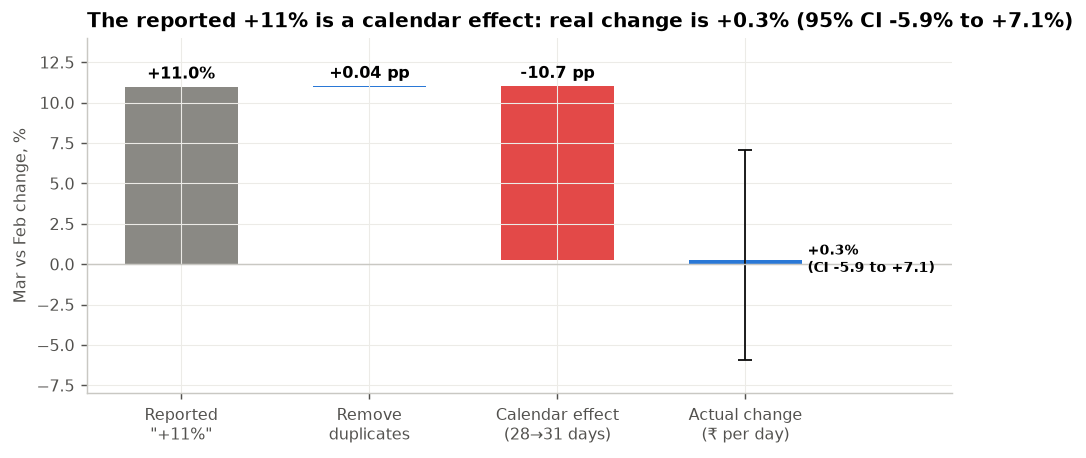

In [8]:
fig, ax = plt.subplots(figsize=(7.5,3.6))
labels = ['Reported\n"+11%"', 'Remove\nduplicates', 'Calendar effect\n(28→31 days)', 'Actual change\n(₹ per day)']
ax.bar(0, rep, color=GRAY, width=0.6); ax.bar(1, dedup-rep, bottom=rep, color=BLUE, width=0.6)
ax.bar(2, perday-dedup, bottom=dedup, color=RED, width=0.6); ax.bar(3, perday, color=BLUE, width=0.6)
ax.errorbar(3, perday, yerr=[[perday-lo],[hi-perday]], color=INK, capsize=4, lw=1)
ax.text(0, rep+0.5, f'+{rep:.1f}%', ha='center', fontweight='bold'); ax.text(1, dedup+0.5, f'{dedup-rep:+.2f} pp', ha='center', fontweight='bold')
ax.text(2, dedup+0.5, f'{perday-dedup:+.1f} pp', ha='center', fontweight='bold')
ax.text(3.33, perday, f'+{perday:.1f}%\n(CI {lo:+.1f} to {hi:+.1f})', va='center', ha='left', fontweight='bold', fontsize=8)
ax.set_xticks(range(4), labels); ax.axhline(0,color='#c9c8c3',lw=0.8); ax.set_ylabel('Mar vs Feb change, %')
ax.set_title(f'The reported +11% is a calendar effect: real change is {perday:+.1f}% (95% CI {lo:+.1f}% to {hi:+.1f}%)', loc='left')
ax.set_xlim(-0.5,4.1); ax.set_ylim(-8, 14); plt.tight_layout(); fig.savefig(CH/'01_waterfall_11pct.png', bbox_inches='tight'); plt.show()

### 4.2 Is there *any* trend? (Newey-West standard errors, robust to serial correlation)

In [9]:
daily['t']=(daily.day_ist-daily.day_ist.min()).dt.days
m_tr = smf.ols('net_collections ~ t + C(weekday)', daily).fit(cov_type='HAC', cov_kwds={'maxlags':7})
mean_d = daily.net_collections.mean()
slope = 30*m_tr.params.t/mean_d*100; ci = 30*m_tr.conf_int().loc['t'].values/mean_d*100
anova = st.f_oneway(*[g.net_collections.values for _,g in daily.groupby('m')])
lb = sm.stats.acorr_ljungbox(daily.net_collections - daily.net_collections.mean(), lags=[7], return_df=True)
print(f'Trend: {slope:+.2f}% per month (HAC 95% CI {ci[0]:+.2f}% to {ci[1]:+.2f}%), weekday-controlled')
print(f'ANOVA across months: F={anova.statistic:.2f}, p={anova.pvalue:.2f};  Ljung-Box(7) p={lb.lb_pvalue.iloc[0]:.2f}')

Trend: -0.36% per month (HAC 95% CI -1.06% to +0.33%), weekday-controlled
ANOVA across months: F=0.48, p=0.82;  Ljung-Box(7) p=0.20


### 4.3 The same seven months under every candidate definition (consistent population)

In [10]:
comp = k[['month_start','reported_collections','net_collections','net_collections_per_day','recovery_per_account',
          'recovery_rate_pct','paying_account_rate_pct','recovery_rate_survivor_denominator_pct']].copy()
for c_ in ['reported_collections','net_collections','net_collections_per_day','recovery_per_account','recovery_rate_pct',
           'paying_account_rate_pct','recovery_rate_survivor_denominator_pct']:
    comp[c_+'_mom%'] = 100*(comp[c_]/comp[c_].shift(1)-1)
show = comp[['month_start']+[c for c in comp.columns if c.endswith('_mom%')]].round(1)
display(show)
show.to_csv(MARTS/'mom_by_definition.csv', index=False)

,month_start,reported_collections_mom%,net_collections_mom%,net_collections_per_day_mom%,recovery_per_account_mom%,recovery_rate_pct_mom%,paying_account_rate_pct_mom%,recovery_rate_survivor_denominator_pct_mom%
0,2026-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-02-01,-8.9,-9.1,0.6,-9.1,-9.1,-8.5,1.6
2,2026-03-01,11.0,11.0,0.3,11.0,11.0,11.3,20.9
3,2026-04-01,-7.7,-7.3,-4.2,-7.3,-7.3,-4.8,0.1
4,2026-05-01,4.8,5.2,1.8,5.2,5.2,1.7,12.1
5,2026-06-01,-4.5,-4.7,-1.5,-4.7,-4.7,-2.5,0.4
6,2026-07-01,6.5,6.7,3.2,6.7,6.7,2.1,10.3


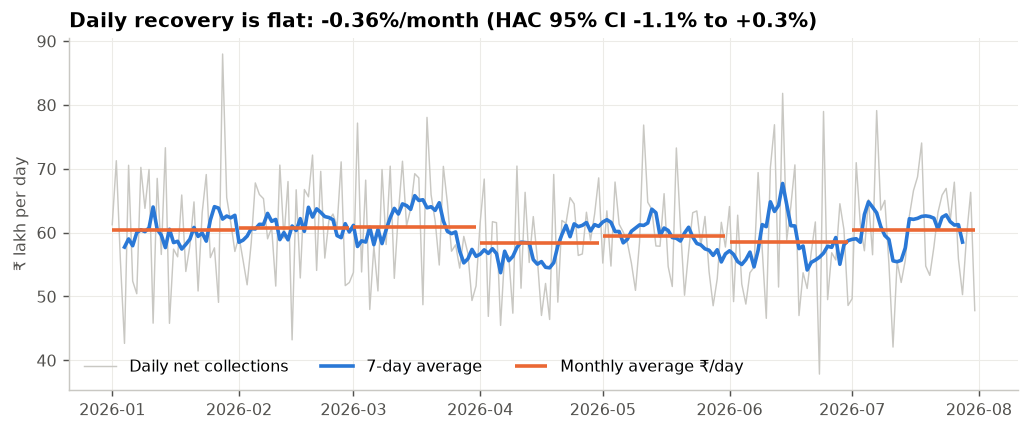

In [11]:
fig, ax = plt.subplots(figsize=(8,3.4))
roll = daily.set_index('day_ist').net_collections.rolling(7, center=True).mean()
ax.plot(daily.day_ist, cr(daily.net_collections)*100, color='#c9c8c3', lw=0.8, label='Daily net collections')
ax.plot(roll.index, cr(roll)*100, color=BLUE, lw=2, label='7-day average')
for i,r in k.iterrows():
    ax.hlines(cr(r.net_collections_per_day)*100, r.month_start, r.month_start+pd.offsets.MonthEnd(0), color=ORANGE, lw=2,
              label='Monthly average ₹/day' if i==0 else None)
ax.set_ylabel('₹ lakh per day'); ax.set_title(f'Daily recovery is flat: {slope:+.2f}%/month (HAC 95% CI {ci[0]:+.1f}% to {ci[1]:+.1f}%)', loc='left')
ax.legend(frameon=False, loc='lower left', ncol=3); plt.tight_layout(); fig.savefig(CH/'02_daily_trend.png', bbox_inches='tight'); plt.show()

**STRONG EVIDENCE: the 11% improvement is not real.**
* **March vs February:** +11.0% as reported, but **+0.3% per day** once the calendar is accounted for (95% CI −5.9% to +7.1%; p = 0.93). The weekday-adjusted figure is essentially the same, and there is no weekday effect to adjust for (§4.1).
* **Jan–Jul trend:** controlling for weekday and using serial-correlation-robust errors, the trend is ≈0. Month means are statistically indistinguishable (ANOVA p = 0.82).
* **Every definition tells the same story** on a consistent population (all 30,000 accounts, every month): per-day recovery, recovery per account, recovery rate and paying-account rate. The swings in month totals track the number of days in the month.
* **The only definition that "improves" steadily** is the status-based denominator. That is a measurement artefact (§3 G), not performance.

The defensible headline is: *"Recovery is flat at ≈₹18 Cr/month (≈₹6 lakh/day), 1.7% of the book per month."*

### 4.4 Verdict on the claim
| Possible verdict | Applies? | Why |
|---|---|---|
| Correct | No | Recovery per day, per account and as a rate did not improve |
| Partially correct | Only arithmetically | One month pair (Feb→Mar) does show +11% in raw totals |
| **Misleading** | **Yes** | The +11% is produced by 31 vs 28 days. It is also not "month-on-month" in any sustained sense: the same formula gives −8.9%, +11.0%, −7.7%, +4.8%, −4.5%, +6.5% across the six month pairs |
| Incorrect | As a statement about performance, yes | Per-day change +0.3% (CI −5.9% to +7.1%) |
| Impossible to verify | No, with one caveat | The business formula was not disclosed, so the reconstruction is strong evidence, not proof of what they computed |

**Sensitivity to what counts as cash.** The conclusion does not depend on excluding PENDING payments (cell below).

In [12]:
sens = Q('''select date_trunc('month', event_at_ist)::date m,
                   sum(amount) filter (where payment_status='SUCCESS') success_only,
                   sum(amount) filter (where payment_status in ('SUCCESS','PENDING')) success_plus_pending,
                   sum(amount) filter (where payment_status <> 'FAILED') all_but_failed
            from cln.payments where event_at_ist >= '2026-02-01' and event_at_ist < '2026-04-01' group by 1 order by 1''')
out = {c_: 100*((sens[c_].iloc[1]/31)/(sens[c_].iloc[0]/28)-1) for c_ in ['success_only','success_plus_pending','all_but_failed']}
print('Mar vs Feb per-day change under alternative cash definitions (%):', {k_: round(v,2) for k_,v in out.items()})

Mar vs Feb per-day change under alternative cash definitions (%): {'success_only': np.float64(0.29), 'success_plus_pending': np.float64(0.0), 'all_but_failed': np.float64(0.73)}


## 5. KPI definitions and the collections funnel

In [13]:
kp = k[['month_start','contact_rate_incl_voicemail_pct','contact_rate_pct','rpc_rate_pct','ptp_rate_pct',
        'ptp_kept_reported_pct','ptp_kept_verified_pct','recovery_rate_pct','recovery_per_account','recovery_per_agent_hour',
        'complaints_per_1000_accounts']]
display(kp.round(2))
fn = Q('select * from ana.funnel_monthly'); display(fn)
rpc_no_answer = Q('''select 100*avg((n_rpc>0 and n_calls_answered=0)::int) filter (where n_rpc>0) pct
                      from gld.account_month where is_complete''').iloc[0,0]
print(f'Accounts with a right-party-contact disposition but NO answered call in the same month: {rpc_no_answer:.0f}%')
print(f"Paying account-months with no touch of any kind that month: {100*fn.accounts_paid_without_any_touch.sum()/fn.accounts_paid.sum():.0f}%")

,month_start,contact_rate_incl_voicemail_pct,contact_rate_pct,rpc_rate_pct,ptp_rate_pct,ptp_kept_reported_pct,ptp_kept_verified_pct,recovery_rate_pct,recovery_per_account,recovery_per_agent_hour,complaints_per_1000_accounts
0,2026-01-01,40.21,20.07,65.51,35.39,48.52,3.81,1.78,6240.97,16966.20,37.77
1,2026-02-01,39.87,19.79,65.55,33.92,50.72,3.11,1.62,5671.42,16248.06,34.47
2,2026-03-01,39.51,19.97,66.84,33.85,49.60,3.03,1.80,6297.08,17065.95,39.30
3,2026-04-01,39.09,19.35,65.57,34.53,50.08,3.69,1.67,5837.93,16620.08,36.70
4,2026-05-01,40.58,20.32,66.81,33.00,49.30,4.59,1.76,6141.68,17079.68,36.83
5,2026-06-01,39.98,20.47,66.33,33.49,49.43,4.51,1.67,5851.99,16577.62,36.10
6,2026-07-01,39.99,19.40,66.54,32.53,49.12,3.04,1.79,6241.41,16806.65,35.83


,month_start,accounts_in_book,accounts_dialled,accounts_answered,accounts_rpc,accounts_with_ptp,accounts_paid,accounts_paid_without_any_touch
0,2026-01-01,30000,9629,2246,3079,2430,2374,894
1,2026-02-01,30000,8927,2033,2764,2145,2173,868
2,2026-03-01,30000,9764,2276,3095,2411,2419,874
3,2026-04-01,30000,9413,2104,2974,2376,2304,863
4,2026-05-01,30000,9669,2285,3155,2413,2344,871
5,2026-06-01,30000,9326,2218,3036,2366,2286,884
6,2026-07-01,30000,9600,2170,3060,2497,2335,866


Accounts with a right-party-contact disposition but NO answered call in the same month: 93%
Paying account-months with no touch of any kind that month: 38%


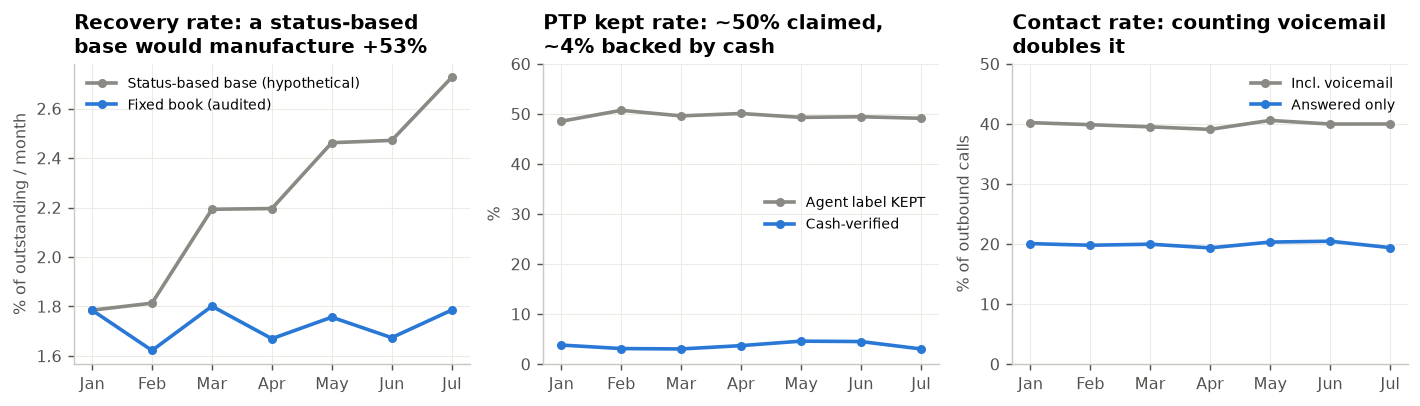

In [14]:
fig, axes = plt.subplots(1,3, figsize=(11,3.2)); x = k.month_start.dt.strftime('%b')
ax=axes[0]; ax.plot(x, k.recovery_rate_survivor_denominator_pct, color=GRAY, lw=2, marker='o', ms=4, label='Status-based base (hypothetical)')
ax.plot(x, k.recovery_rate_pct, color=BLUE, lw=2, marker='o', ms=4, label='Fixed book (audited)')
ax.set_title('Recovery rate: a status-based\nbase would manufacture +53%', loc='left'); ax.set_ylabel('% of outstanding / month'); ax.legend(frameon=False, fontsize=8)
ax=axes[1]; ax.plot(x, k.ptp_kept_reported_pct, color=GRAY, lw=2, marker='o', ms=4, label='Agent label KEPT')
ax.plot(x, k.ptp_kept_verified_pct, color=BLUE, lw=2, marker='o', ms=4, label='Cash-verified')
ax.set_title('PTP kept rate: ~50% claimed,\n~4% backed by cash', loc='left'); ax.set_ylabel('%'); ax.legend(frameon=False, fontsize=8); ax.set_ylim(0,60)
ax=axes[2]; ax.plot(x, k.contact_rate_incl_voicemail_pct, color=GRAY, lw=2, marker='o', ms=4, label='Incl. voicemail')
ax.plot(x, k.contact_rate_pct, color=BLUE, lw=2, marker='o', ms=4, label='Answered only')
ax.set_title('Contact rate: counting voicemail\ndoubles it', loc='left'); ax.set_ylabel('% of outbound calls'); ax.legend(frameon=False, fontsize=8); ax.set_ylim(0,50)
plt.tight_layout(); fig.savefig(CH/'03_metric_definitions.png', bbox_inches='tight'); plt.show()

* **FACT: the funnel is not a funnel.** More accounts carry a right-party-contact (RPC) disposition than had an answered call in the same month. **93%** of accounts with an RPC disposition had **no answered call** that month. Dispositions are logged without a matching conversation. This is another symptom of the broken `call_id` links (§3). Call-level conversion rates (answered → PTP → paid) **cannot be measured** from this data, so v2 reports account-level counts only.
* **FACT:** 38% of paying account-months had **no** touch of any kind that month. A large share of recovery is organic, and last-touch attribution would credit it to whatever happened to precede it.
* Definitions and rationale for every KPI: `docs/metric_definitions.md`.

## 6. Why did it (not) happen? Drivers
### 6.1 Portfolio, DPD, product, geography, borrower segment

In [15]:
am = Q('select * from gld.account_month where is_complete'); am['month'] = am.month_start.astype(str)
rows=[]
for dim in ['dpd_bucket','loan_type','risk_segment','state','account_timezone','snapshot_status']:
    ct = pd.crosstab(am[dim], am.paid_flag); p = st.chi2_contingency(ct)[1]; rates = (ct[True]/ct.sum(axis=1)*100)
    rows.append({'dimension':dim,'levels':len(ct),'min_paying_rate_%':rates.min(),'max_paying_rate_%':rates.max(),'chi2_p':p})
display(pd.DataFrame(rows).round(3))
seg = Q('''select dpd_bucket, month_start, sum(collected)/any_value(days_in_month) per_day
           from gld.account_month where month_start in ('2026-02-01','2026-03-01') group by all''')
sp = seg.pivot(index='dpd_bucket', columns='month_start', values='per_day'); sp.columns=['feb','mar']
sp['per_day_change_%']=100*(sp.mar/sp.feb-1); display(sp.round(1))
mix = Q('''select month_start, dpd_bucket, count(*) filter (where n_touches>0) worked, sum(collected) filter (where n_touches>0) coll
           from gld.account_month where month_start in ('2026-01-01','2026-07-01') group by all''')
a = mix[mix.month_start=='2026-01-01'].set_index('dpd_bucket'); b = mix[mix.month_start=='2026-07-01'].set_index('dpd_bucket')
wa_, wb_ = a.worked/a.worked.sum(), b.worked/b.worked.sum(); ra, rb = a.coll/a.worked, b.coll/b.worked
print(f'₹ per worked account Jan {(wa_*ra).sum():,.0f} -> Jul {(wb_*rb).sum():,.0f}: mix effect {((wb_-wa_)*(ra+rb)/2).sum():+,.0f}, rate effect {((rb-ra)*(wa_+wb_)/2).sum():+,.0f}')
coh = Q('''select date_trunc('quarter', a.opened_at_local)::date vintage, m.month_start, 100*avg(m.paid_flag::int) paying_rate
           from gld.account_month m join cln.dim_account a using(account_id) where m.is_complete group by all''')
display(coh.pivot(index='vintage', columns='month_start', values='paying_rate').round(2))

,dimension,levels,min_paying_rate_%,max_paying_rate_%,chi2_p
0,dpd_bucket,5,7.571,8.047,0.105
1,loan_type,5,7.569,7.967,0.282
2,risk_segment,4,7.620,7.908,0.265
3,state,10,7.440,8.053,0.324
4,account_timezone,3,7.696,7.774,0.857
5,snapshot_status,4,7.686,7.776,0.938


,feb,mar,per_day_change_%
dpd_bucket,,,
0 (current),524027.7,553715.6,5.7
01-30,2104228.9,2333496.1,10.9
31-60,1174374.9,1089964.7,-7.2
61-90,1127558.4,1074555.1,-4.7
90+,1146326.3,1042216.1,-9.1


₹ per worked account Jan 6,235 -> Jul 6,261: mix effect +1, rate effect +24


month_start,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01
vintage,,,,,,,
2024-01-01,7.40,7.05,7.62,7.52,7.40,7.30,7.70
2024-04-01,7.56,7.35,7.59,8.20,8.04,7.64,7.85
2024-07-01,7.88,6.89,8.38,7.81,7.21,7.66,8.26
2024-10-01,7.46,7.91,7.96,7.86,7.94,8.04,8.11
2025-01-01,8.88,6.92,8.80,7.17,7.17,7.50,7.04
2025-04-01,7.55,6.68,8.27,7.79,8.58,7.37,8.50
2025-07-01,8.32,7.69,7.41,7.66,8.01,8.11,7.28
2025-10-01,8.41,7.56,8.69,7.33,8.41,7.17,7.41


* **STRONG EVIDENCE: no segment drives performance.** Paying rates fall between 7.4% and 8.1% in every DPD bucket, product, risk segment, state and account timezone, and none of the differences is significant (all χ² p > 0.10). DPD normally has the steepest recovery gradient in collections; here it has none. **HYPOTHESIS:** DPD and risk are stale snapshots rather than live fields.
* **FACT: no Simpson's paradox and no mix effect.** Within each DPD bucket, the Feb→Mar per-day change scatters both ways around the aggregate +0.3%. That is sampling noise; a Simpson's paradox would need every segment to move *against* the aggregate. One caution: a reporter could cherry-pick the 1–30 DPD bucket (+10.9%) to "confirm" the 11%. The Jan→Jul mix effect is ≈₹1 per account.
* **FACT: no cohort effect.** The vintage × month table shows no ordering by origination quarter. No new portfolio was acquired during the window.

### 6.2 Campaign and targeting strategy
Calls cannot be linked to their dispositions (the `call_id`s are broken), so the cleanest campaign test is this: once an account is **targeted**, does it pay within 7 days?

In [16]:
cs = Q('select * from ana.campaign_summary'); display(cs.round(2))
ctab = Q('select target_status, paid_7d from ana.campaign_targeting')
for dim in ['strategy_version','target_definition','campaign_name','recommended_channel','target_status']:
    d_ = Q(f'select {dim} lvl, paid_7d from ana.campaign_targeting'); p = st.chi2_contingency(pd.crosstab(d_.lvl, d_.paid_7d))[1]
    print(f'{dim:20s} chi2 p = {p:.3f}')
ts = Q("select target_status in ('CONTACTED') contacted, avg(paid_7d::int)*100 pay_pct, count(*) n from ana.campaign_targeting group by 1")
display(ts.round(3))

,dim,lvl,targetings,pay_within_7d_pct
0,campaign_channel,FIELD,6525,2.11
1,campaign_channel,MIXED,8410,2.01
2,campaign_channel,SMS,10128,1.78
3,campaign_channel,VOICE,7203,1.68
4,campaign_channel,WHATSAPP,10980,1.81
5,campaign_name,30DPD_W1,10158,2.10
6,campaign_name,60DPD_INTENT,6565,1.77
7,campaign_name,BOUNCE,8988,1.85
8,campaign_name,DIGITAL_FOLLOWUP,7486,1.71
9,campaign_name,NPA_RECOVERY,10049,1.83


strategy_version     chi2 p = 0.584
target_definition    chi2 p = 0.113
campaign_name        chi2 p = 0.356
recommended_channel  chi2 p = 0.402
target_status        chi2 p = 0.367


,contacted,pay_pct,n
0,False,1.906,32427
1,True,1.747,10819


* **Strategy version** (legacy / v1 / v2 / v3) and **campaign name** are not associated with payment within 7 days at conventional significance (see the χ² p-values above).
* **Target definition:** HIGH_RISK targets pay least (1.55%) and DPD≥30 targets most (2.09%). Read this as a CORRELATION only: the label does not match the accounts targeted (§3), so it does not describe a real segment.
* **The most informative comparison: targeted accounts that were contacted vs targeted accounts that were skipped, expired or left queued.** Both groups were picked by the same targeting engine, so the comparison partly controls for selection. Contacted targets pay **no more** than uncontacted ones. **CORRELATION**, consistent with §6.3: the contact itself adds nothing measurable.

### 6.3 Channel effect in rupees (the input the investment model needs)
Regression on the fixed-cohort panel: ₹ collected per account-month on that month's touches by channel, with month, DPD and product fixed effects and standard errors clustered by account.

In [17]:
m_rs = smf.ols('collected ~ n_calls + n_calls_answered + n_whatsapp + n_sms + n_field_visits + C(month) + C(dpd_bucket) + C(loan_type)',
               am).fit(cov_type='cluster', cov_kwds={'groups': am.account_id})
eff = pd.DataFrame({'rs_per_touch': m_rs.params.filter(regex='^n_'), 'ci_low': m_rs.conf_int().loc[m_rs.params.filter(regex='^n_').index,0],
                    'ci_high': m_rs.conf_int().loc[m_rs.params.filter(regex='^n_').index,1], 'p': m_rs.pvalues.filter(regex='^n_')})
ANS = k.contact_rate_pct.mean()/100
tdial = m_rs.t_test(f'n_calls + {ANS:.4f}*n_calls_answered = 0')
eff.loc['dial (incl. answer chance)'] = [float(tdial.effect[0]), *tdial.conf_int(0.05)[0], float(tdial.pvalue)]
display(eff.round(1)); eff.round(2).to_csv(MARTS/'channel_effect_rs_per_touch.csv')
conv = Q('select * from ana.channel_conversion'); base = Q('select * from ana.channel_baseline').iloc[0,0]
conv['lift_vs_baseline_pp'] = conv.pay_within_7d_pct - base
conv['ci95_pp'] = 1.96*np.sqrt(conv.pay_within_7d_pct/100*(1-conv.pay_within_7d_pct/100)/conv.touches)*100
print(f'No-touch baseline P(pay within 7 days of a random day) = {base:.2f}%'); display(conv.round(3))
# Robustness: same-month touches can happen AFTER the payment. Use last month's touches instead.
lag = am.sort_values(['account_id','month_start']).copy()
for c_ in ['n_calls','n_calls_answered','n_whatsapp','n_sms','n_field_visits']:
    lag['lag_'+c_] = lag.groupby('account_id')[c_].shift(1)
lag = lag.dropna(subset=['lag_n_calls'])
m_lag = smf.ols('collected ~ lag_n_calls + lag_n_calls_answered + lag_n_whatsapp + lag_n_sms + lag_n_field_visits + C(month) + C(dpd_bucket) + C(loan_type)',
                lag).fit(cov_type='cluster', cov_kwds={'groups': lag.account_id})
ix = m_lag.params.filter(regex='^lag_').index
display(pd.DataFrame({'rs_per_touch_last_month': m_lag.params[ix], 'ci_low': m_lag.conf_int().loc[ix,0], 'ci_high': m_lag.conf_int().loc[ix,1], 'p': m_lag.pvalues[ix]}).round(1))

,rs_per_touch,ci_low,ci_high,p
n_calls,1.3,-188.0,190.6,1.0
n_calls_answered,257.0,-183.2,697.2,0.3
n_whatsapp,149.4,-53.0,351.9,0.1
n_sms,-26.2,-258.7,206.3,0.8
n_field_visits,5.7,-310.6,322.0,1.0
dial (incl. answer chance),52.5,-118.3,223.3,0.5


No-touch baseline P(pay within 7 days of a random day) = 1.83%


,channel,touches,pay_within_7d_pct,pay_within_7d_engaged_pct,pay_within_7d_not_engaged_pct,lift_vs_baseline_pp,ci95_pp
0,CALL,79915,1.833,1.911,1.814,0.008,0.093
1,FIELD,24129,1.803,1.632,2.142,-0.023,0.168
2,SMS,43393,1.821,1.928,1.785,-0.005,0.126
3,WHATSAPP,57817,1.766,1.828,1.704,-0.060,0.107


,rs_per_touch_last_month,ci_low,ci_high,p
lag_n_calls,30.0,-176.5,236.6,0.8
lag_n_calls_answered,-37.4,-501.6,426.8,0.9
lag_n_whatsapp,112.6,-107.1,332.2,0.3
lag_n_sms,97.9,-149.5,345.4,0.4
lag_n_field_visits,-136.0,-467.8,195.8,0.4


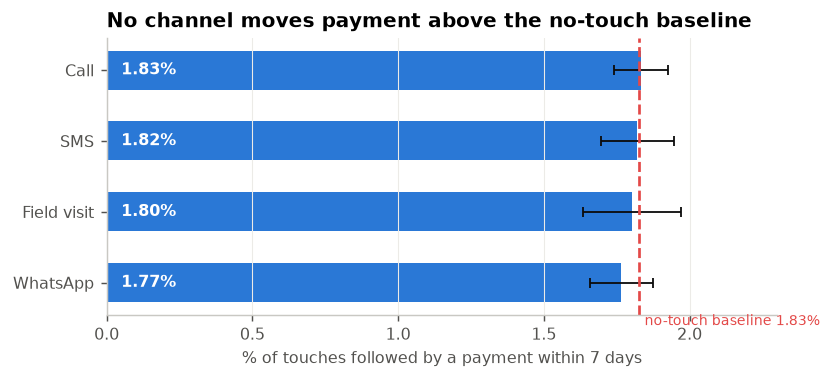

In [18]:
fig, ax = plt.subplots(figsize=(6.5,3))
order = conv.sort_values('pay_within_7d_pct'); names = {'CALL':'Call','SMS':'SMS','FIELD':'Field visit','WHATSAPP':'WhatsApp'}
ax.barh(order.channel.map(names), order.pay_within_7d_pct, color=BLUE, height=0.55, xerr=order.ci95_pp, error_kw={'ecolor':INK,'lw':1,'capsize':3})
ax.axvline(base, color=RED, lw=1.5, ls='--'); ax.text(base+0.02, -0.6, f'no-touch baseline {base:.2f}%', color=RED, fontsize=8)
for i,v in enumerate(order.pay_within_7d_pct): ax.text(0.05, i, f'{v:.2f}%', va='center', color='white', fontweight='bold')
ax.set_xlabel('% of touches followed by a payment within 7 days'); ax.set_xlim(0,2.3)
ax.set_title('No channel moves payment above the no-touch baseline', loc='left'); ax.grid(axis='y', visible=False)
plt.tight_layout(); fig.savefig(CH/'04_channel_lift.png', bbox_inches='tight'); plt.show()

* **STRONG EVIDENCE: no channel has a statistically detectable effect on rupees collected.** Every per-touch coefficient has a 95% CI that includes zero. WhatsApp has the most positive point estimate, but it is not significant (see table): treat it as a weak CORRELATION, not a finding.
* **The confidence intervals are wide**, roughly ±₹200–₹500 per touch. The data therefore **cannot rule out** a modest positive effect, and that matters for cheap channels. §8 uses the upper bounds for exactly this reason.
* **Payment within 7 days of a touch** is 1.77–1.83% for every channel, identical to the 1.83% after a random day.
* **Timing robustness.** A touch in the same month can come after the payment. Re-estimating with the *previous* month's touches (table above) gives the same picture: no channel is significant.
* **Selection caveat:** touches were not randomly assigned, so a zero association could in principle hide a positive effect offset by targeting harder accounts. Two things make that unlikely: targeting is not correlated with DPD or risk, and contacted vs skipped targets are equal (§6.2). Only a randomised test settles it (§9).

### 6.4 Is there anything to *target* on? (heterogeneity and predictability)
Better targeting pays off only if (a) the effect of contact **differs** across accounts, or (b) payment is **predictable**, so effort can be steered. Both conditions are testable.

In [19]:
het = {}
for dim in ['dpd_bucket','loan_type','risk_segment']:
    mi = smf.ols(f'collected ~ (n_calls_answered + n_whatsapp + n_sms + n_field_visits)*C({dim}) + n_calls + C(month)', am
                 ).fit(cov_type='cluster', cov_kwds={'groups': am.account_id})
    names=[n for n in mi.params.index if ':' in n]
    het[dim] = mi.wald_test(', '.join(f'{n} = 0' for n in names), scalar=True).pvalue
print('Joint test that channel effects differ by segment (p-values):', {k_: round(v,3) for k_,v in het.items()})
# predictability: does history + segment predict who pays in July? (holdout month)
hist = am[am.month_start < pd.Timestamp('2026-07-01')].groupby('account_id').agg(prior_pays=('paid_flag','sum'), prior_rs=('collected','sum'),
        prior_touches=('n_touches','sum')).reset_index()
jul = am[am.month_start == pd.Timestamp('2026-07-01')][['account_id','paid_flag','dpd_bucket','loan_type','risk_segment','outstanding_amount']].merge(hist, on='account_id')
jul = jul.sort_values('account_id').reset_index(drop=True); jul['y']=jul.paid_flag.astype(int)
train, test = jul.sample(frac=0.5, random_state=1), None
test = jul.drop(train.index)
lg = smf.logit('y ~ prior_pays + np.log1p(prior_rs) + prior_touches + C(dpd_bucket) + C(loan_type) + C(risk_segment) + np.log(outstanding_amount)', train).fit(disp=0)
score = lg.predict(test); pos, neg = score[test.y==1], score[test.y==0]
auc = st.mannwhitneyu(pos, neg).statistic/(len(pos)*len(neg))
print(f'Out-of-sample AUC predicting July payment from Jan–Jun history + segments: {auc:.3f}  (0.5 = no better than chance)')
w = am.pivot(index='account_id', columns='month_start', values='collected')
print(f'Average month-to-month correlation of an account\'s collections: {np.nanmean(np.corrcoef(w.values.T)[np.triu_indices(7,1)]):.4f}')

Joint test that channel effects differ by segment (p-values): {'dpd_bucket': np.float64(0.298), 'loan_type': np.float64(0.482), 'risk_segment': np.float64(0.391)}


Out-of-sample AUC predicting July payment from Jan–Jun history + segments: 0.501  (0.5 = no better than chance)
Average month-to-month correlation of an account's collections: -0.0000


* **STRONG EVIDENCE: no heterogeneity.** The joint tests that channel effects differ by DPD bucket, product or risk segment are all far from significant (p-values above).
* **STRONG EVIDENCE: payment is not predictable from anything in the data.** A logistic model on payment history and segment predicts July payers at an out-of-sample AUC of ≈0.5, which is chance. An account's collections in one month are uncorrelated with the next.
* **Implication for "better targeting".** On today's data there is nothing to target *on*. A targeting investment would first have to **create** signal: new data such as bureau, income or bank-statement features, plus experiments. That is why v1's recommendation of targeting is withdrawn in v2: its precondition was never tested, and when tested it fails.

### 6.5 Calling time, telephony vendor, attempt frequency

In [20]:
hr = Q('select * from ana.call_hour'); vd = Q('select * from ana.vendor'); af = Q('select * from ana.attempt_frequency')
ct = np.array([(hr.calls*hr.answer_rate_pct/100).round(), hr.calls-(hr.calls*hr.answer_rate_pct/100).round()]).T
ctv = np.array([(vd.calls*vd.answer_rate_pct/100).round(), vd.calls-(vd.calls*vd.answer_rate_pct/100).round()]).T
print(f'Answer rate by IST hour {hr.answer_rate_pct.min():.1f}–{hr.answer_rate_pct.max():.1f}% (chi2 p={st.chi2_contingency(ct)[1]:.2f});'
      f' by vendor account {vd.answer_rate_pct.min():.1f}–{vd.answer_rate_pct.max():.1f}% (chi2 p={st.chi2_contingency(ctv)[1]:.2f})')
display(af.round(2))
print('Calls placed outside 08:00-19:00 IST: %.1f%%' % Q("select 100*avg(flag_outside_8am_7pm_ist::int) from cln.calls where direction='OUTBOUND'").iloc[0,0])

Answer rate by IST hour 18.6–21.6% (chi2 p=0.16); by vendor account 19.2–21.1% (chi2 p=0.45)


,attempts_bucket,account_months,paying_rate_pct,collected_per_account_month
0,0,120929,7.70,6050.46
1,1-2,85208,7.79,6060.24
2,3-5,3862,7.20,5286.78
3,6+,1,0.00,0.00


Calls placed outside 08:00-19:00 IST: 54.1%


* **STRONG EVIDENCE: the hour of the call and the telephony vendor do not change answer rates.** The best vendor is about 1 pp above average, and the difference is not significant. A telephony upgrade has no observed spread to capture.
* **CORRELATION: more dialling buys nothing.** Paying rates are flat across 0, 1–2 and 3–5 dial attempts per account-month.
* **FACT: compliance exposure.** 54% of outbound calls are placed outside 08:00–19:00 IST, the window RBI's recovery-agent and fair-practices guidance allows for calls. This is a regulatory risk to fix regardless of the investment decision, at near-zero cost (a dialer schedule rule).

### 6.6 Agents and tenure

Split-half reliability of agent PTP rate (n=960 agents): r = -0.061 (p=0.06)
Agents outside 99.8% binomial control limits on answer rate: 0 of 1000 (expected by chance ≈ 2.0)


,tenure,calls,answer_rate_pct
0,0-6m,6237,20.59
1,12-24m,42132,19.83
2,24m+,13093,20.09
3,6-12m,19828,19.69


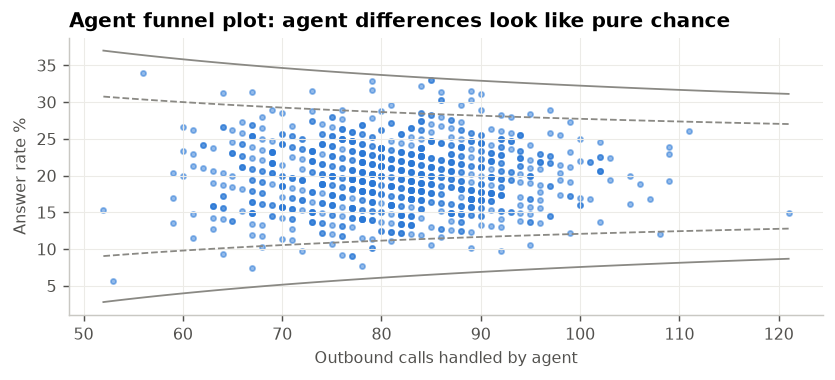

In [21]:
ah = Q('select * from ana.agent_halves where n_h1>=10 and n_h2>=10'); r_, p_ = st.pearsonr(ah.ptp_rate_h1, ah.ptp_rate_h2)
print(f'Split-half reliability of agent PTP rate (n={len(ah)} agents): r = {r_:.3f} (p={p_:.2f})')
ao = Q('select * from ana.agent_outcomes where outbound_calls >= 20')
p0 = ao.answered.sum()/ao.outbound_calls.sum()
ao['z'] = (ao.answered/ao.outbound_calls - p0)/np.sqrt(p0*(1-p0)/ao.outbound_calls)
print(f'Agents outside 99.8% binomial control limits on answer rate: {(ao.z.abs()>3.09).sum()} of {len(ao)} (expected by chance ≈ {0.002*len(ao):.1f})')
ten = Q('''select case when tenure_months_asof < 6 then '0-6m' when tenure_months_asof < 12 then '6-12m'
                     when tenure_months_asof < 24 then '12-24m' else '24m+' end tenure, count(*) calls, 100*avg(is_contact::int) answer_rate_pct
           from ana.agent_call_tenure group by 1 order by 1'''); display(ten.round(2))
fig, ax = plt.subplots(figsize=(6.5,3))
ax.scatter(ao.outbound_calls, 100*ao.answered/ao.outbound_calls, s=8, color=BLUE, alpha=0.5)
nn = np.linspace(ao.outbound_calls.min(), ao.outbound_calls.max(), 100)
for zz in [1.96, 3.09]:
    ax.plot(nn, 100*(p0+zz*np.sqrt(p0*(1-p0)/nn)), color=GRAY, lw=1, ls='--' if zz<3 else '-')
    ax.plot(nn, 100*(p0-zz*np.sqrt(p0*(1-p0)/nn)), color=GRAY, lw=1, ls='--' if zz<3 else '-')
ax.set_xlabel('Outbound calls handled by agent'); ax.set_ylabel('Answer rate %')
ax.set_title('Agent funnel plot: agent differences look like pure chance', loc='left')
plt.tight_layout(); fig.savefig(CH/'07_agent_funnel_plot.png', bbox_inches='tight'); plt.show()

* **STRONG EVIDENCE: agent rankings are noise.** An agent's PTP rate in the first half of the period does not predict their rate in the second half. The number of agents outside binomial control limits matches what chance alone would produce.
* **Tenure cannot be measured reliably.** Each agent_id carries ~30 conflicting `joined_at` values (§3 E). The as-of (SCD-2) estimate shows no gradient. **No evidence that more or more-experienced agents would raise recovery.**

### 6.7 Attribution-window bias

,k,payments_with_touch_pct,random_days_with_touch_pct
0,1,3.1,3.2
1,3,9.0,9.2
2,7,19.5,20.4
3,14,35.0,36.2
4,30,58.5,60.2


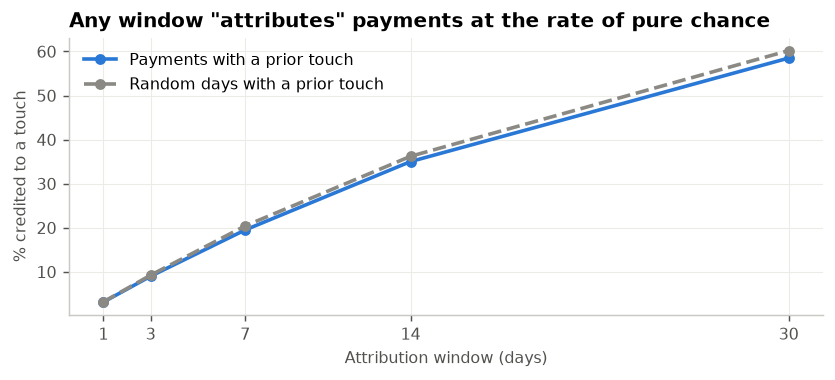

In [22]:
con.execute('select setseed(0.42)')
aw = Q('''
with pay as (select account_id, event_at_ist ts from gld.fct_payment),
rnd as (select a.account_id, (date '2026-01-08' + to_days(cast(floor(random()*200) as int)))::timestamp + interval 12 hour ts
        from (select account_id from cln.dim_account) a, range(3)),
w as (select unnest([1,3,7,14,30]) k)
select k,
  (select 100*avg((exists(select 1 from gld.fct_touch t where t.account_id=p.account_id and t.event_at_ist < p.ts and t.event_at_ist >= p.ts - to_days(k)))::int) from pay p) payments_with_touch_pct,
  (select 100*avg((exists(select 1 from gld.fct_touch t where t.account_id=r.account_id and t.event_at_ist < r.ts and t.event_at_ist >= r.ts - to_days(k)))::int) from rnd r) random_days_with_touch_pct
from w order by k'''); display(aw.round(1))
fig, ax = plt.subplots(figsize=(6.5,3))
ax.plot(aw.k, aw.payments_with_touch_pct, color=BLUE, lw=2, marker='o', ms=5, label='Payments with a prior touch')
ax.plot(aw.k, aw.random_days_with_touch_pct, color=GRAY, lw=2, ls='--', marker='o', ms=5, label='Random days with a prior touch')
ax.set_xlabel('Attribution window (days)'); ax.set_ylabel('% credited to a touch'); ax.set_xticks(aw.k)
ax.set_title('Any window "attributes" payments at the rate of pure chance', loc='left'); ax.legend(frameon=False)
plt.tight_layout(); fig.savefig(CH/'05_attribution_window.png', bbox_inches='tight'); plt.show()

**STRONG EVIDENCE.** The share of payments preceded by a touch rises with the window length (≈20% at 7 days, ≈59% at 30 days), and **tracks the share of random days preceded by a touch at every window.** Under any attribution window, channel credit is coincidence.

## 7. Counterfactual: what if the targeting strategy had not changed?

**Set-up.** The brief asks us to *assume* a mid-year change. Campaigns carry `strategy_version`. We define **NEW = v2/v3** and the **cut-over = 1 Apr 2026**.

**FACT, before any modelling:** the data shows **no visible change in targeting**. The v2/v3 share of targeting rows, the DPD of targeted accounts, the recommended channel and the priority are all constant month to month.

| Element | Choice |
|---|---|
| Unit | account × month (fixed-cohort panel) |
| **Treatment** | accounts targeted by a NEW-strategy campaign in Apr–Jul **and never** in Jan–Mar |
| **Control** | accounts never targeted by a NEW-strategy campaign |
| Excluded | always-treated accounts (NEW before the cut-over) |
| Outcomes | paid in month (0/1); ₹ collected |
| **Identification** | (1) Difference-in-differences with account and month fixed effects plus an event study; (2) robustness: drop January; (3) inverse-propensity-weighted (IPW) post-period comparison on pre-period covariates |
| **Assumptions** | parallel trends (DiD); selection on observables (IPW); no anticipation; SUTVA |
| **Confounders** | DPD and product (absorbed by account FE / used in the propensity model); seasonality and calendar (month FE); time-varying selection (not absorbed) |

In [23]:
tr = Q('''
with g as (select account_id,
              bool_or(targeted_new_strategy and month_start <  '2026-04-01') new_pre,
              bool_or(targeted_new_strategy and month_start >= '2026-04-01') new_post
           from gld.account_month where is_complete group by 1)
select m.account_id, m.month_start, m.paid_flag::int paid, m.collected, m.dpd_bucket, m.loan_type, m.risk_segment,
       case when not g.new_pre and g.new_post then 1 when not g.new_pre and not g.new_post then 0 end treated
from gld.account_month m join g using(account_id) where m.is_complete''').dropna(subset=['treated'])
tr['post'] = (tr.month_start >= pd.Timestamp('2026-04-01')).astype(int); tr['month']=tr.month_start.astype(str)
print(tr.groupby('treated').account_id.nunique().rename('accounts'))
def did(d, y):
    d = d.copy(); d['tp'] = d.treated*d.post
    for c_ in [y,'tp']: d[c_+'_dm'] = d[c_] - d.groupby('account_id')[c_].transform('mean')
    return smf.ols(f'{y}_dm ~ tp_dm + C(month)', d).fit(cov_type='cluster', cov_kwds={'groups': d.account_id})
res = {}
for y in ['paid','collected']:
    m_ = did(tr, y); res[y] = (m_.params.tp_dm, *m_.conf_int().loc['tp_dm'].values, m_.pvalues.tp_dm)
    print(f'DiD ATT on {y}: {m_.params.tp_dm:.4f} (95% CI {res[y][1]:.4f} to {res[y][2]:.4f}), p={res[y][3]:.2f}')
r2 = did(tr[tr.month_start >= pd.Timestamp('2026-02-01')], 'paid')
print(f'Robustness, pre = Feb–Mar only: {r2.params.tp_dm*100:+.2f} pp (95% CI {r2.conf_int().loc["tp_dm",0]*100:+.2f} to {r2.conf_int().loc["tp_dm",1]*100:+.2f}), p={r2.pvalues.tp_dm:.2f}')

treated
0    14739
1     7492
Name: accounts, dtype: int64


DiD ATT on paid: -0.0000 (95% CI -0.0057 to 0.0056), p=0.99


DiD ATT on collected: -28.3985 (95% CI -554.2713 to 497.4744), p=0.92


Robustness, pre = Feb–Mar only: -0.29 pp (95% CI -0.94 to +0.35), p=0.37


,month,coef,lo,hi
0,2026_01,-1.16,-2.23,-0.10
1,2026_02,-0.58,-1.63,0.48
0,2026_03,0.00,0.00,0.00
2,2026_04,-0.32,-1.39,0.75
3,2026_05,-0.48,-1.55,0.59
4,2026_06,-0.57,-1.64,0.49
5,2026_07,-0.96,-2.03,0.12


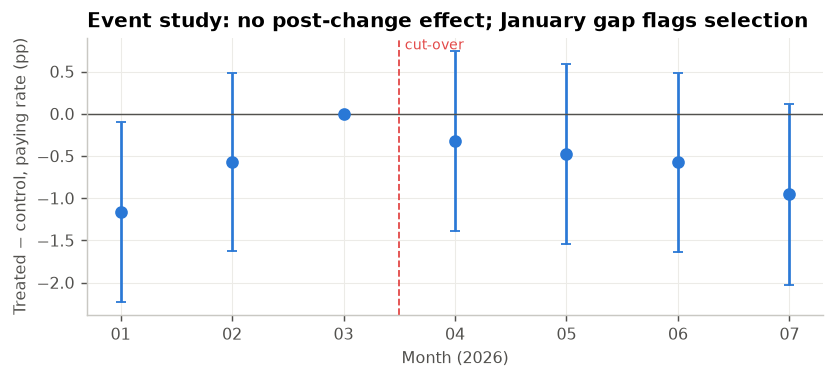

In [24]:
es = tr.copy(); months = sorted(es.month.unique())
for mth in months:
    if mth != '2026-03-01': es['tx_'+mth[:7].replace('-','_')] = ((es.month==mth)&(es.treated==1)).astype(int)
cols = [c_ for c_ in es.columns if c_.startswith('tx_')]
for c_ in cols+['paid']: es[c_+'_dm'] = es[c_]-es.groupby('account_id')[c_].transform('mean')
ev = smf.ols('paid_dm ~ ' + ' + '.join(c_+'_dm' for c_ in cols) + ' + C(month)', es).fit(cov_type='cluster', cov_kwds={'groups':es.account_id})
evt = pd.DataFrame({'month':[c_[3:] for c_ in cols], 'coef':[ev.params[c_+'_dm']*100 for c_ in cols],
                    'lo':[ev.conf_int().loc[c_+'_dm',0]*100 for c_ in cols], 'hi':[ev.conf_int().loc[c_+'_dm',1]*100 for c_ in cols]})
evt = pd.concat([evt, pd.DataFrame({'month':['2026_03'],'coef':[0],'lo':[0],'hi':[0]})]).sort_values('month'); display(evt.round(2))
fig, ax = plt.subplots(figsize=(6.5,3))
ax.errorbar(evt.month.str.replace('2026_',''), evt.coef, yerr=[evt.coef-evt.lo, evt.hi-evt.coef], fmt='o', color=BLUE, ecolor=BLUE, capsize=3, ms=6)
ax.axhline(0, color=INK2, lw=0.8); ax.axvline(2.5, color=RED, lw=1, ls='--'); ax.text(2.55, ax.get_ylim()[1]*0.85, 'cut-over', color=RED, fontsize=8)
ax.set_ylabel('Treated − control, paying rate (pp)'); ax.set_xlabel('Month (2026)')
ax.set_title('Event study: no post-change effect; January gap flags selection', loc='left')
plt.tight_layout(); fig.savefig(CH/'06_did_event_study.png', bbox_inches='tight'); plt.show()

In [25]:
# IPW robustness: propensity of treatment from pre-period behaviour + segments; compare post-period outcomes
pre = tr[tr.post==0].groupby('account_id').agg(pre_paid=('paid','mean'), pre_rs=('collected','mean'), treated=('treated','first'),
        dpd_bucket=('dpd_bucket','first'), loan_type=('loan_type','first'), risk_segment=('risk_segment','first')).reset_index()
post = tr[tr.post==1].groupby('account_id').agg(post_paid=('paid','mean'), post_rs=('collected','mean')).reset_index()
d = pre.merge(post, on='account_id')
ps = smf.logit('treated ~ pre_paid + np.log1p(pre_rs) + C(dpd_bucket) + C(loan_type) + C(risk_segment)', d).fit(disp=0)
d['ps'] = ps.predict(d).clip(0.02, 0.98)
d['w'] = np.where(d.treated==1, 1/d.ps, 1/(1-d.ps))
ipw = smf.wls('post_paid ~ treated', d, weights=d.w).fit(cov_type='HC1')
print(f'Propensity overlap: treated ps {d.ps[d.treated==1].min():.2f}–{d.ps[d.treated==1].max():.2f}, control {d.ps[d.treated==0].min():.2f}–{d.ps[d.treated==0].max():.2f}')
print(f'IPW ATE on post-period monthly paying rate: {ipw.params.treated*100:+.2f} pp (95% CI {ipw.conf_int().loc["treated",0]*100:+.2f} to {ipw.conf_int().loc["treated",1]*100:+.2f})')
post_treated_am = tr.query('treated==1 and post==1').shape[0]
actual_post = Q("select sum(collected) from gld.account_month where month_start between '2026-04-01' and '2026-07-01'").iloc[0,0]
att, att_lo, att_hi = res['collected'][0], res['collected'][1], res['collected'][2]
print(f'Actual Apr–Jul recovery ₹{cr(actual_post):.1f} Cr; counterfactual without the change ₹{cr(actual_post-att*post_treated_am):.1f} Cr '
      f'(95% band ₹{cr(actual_post-att_hi*post_treated_am):.1f}–{cr(actual_post-att_lo*post_treated_am):.1f} Cr)')

Propensity overlap: treated ps 0.31–0.36, control 0.31–0.36
IPW ATE on post-period monthly paying rate: -0.06 pp (95% CI -0.43 to +0.31)
Actual Apr–Jul recovery ₹72.2 Cr; counterfactual without the change ₹72.3 Cr (95% band ₹70.7–73.9 Cr)


**Result: CORRELATION-level evidence of no effect.**
* DiD, the Feb–Mar robustness check and IPW all estimate ≈0 effect on paying rate, with CIs spanning zero.
* The counterfactual Apr–Jul recovery is within a rounding error of actual recovery.

**Is the method appropriate? Partly.**
* **Parallel trends holds only approximately.** January is −1.2 pp for the treated group, with a CI that excludes zero. The business chose which accounts to move, so selection is real.
* **IPW assumes the propensity model captures that selection.** With an AUC ≈0.5 for predicting payment, observed covariates carry little information either way.
* **Treatment is measured with noise.** Campaign labels don't match the accounts targeted (§3), so "strategy" is a noisy proxy.

**Verdict.** The data **cannot** causally identify the effect of a targeting change. The three methods agree on "no detectable effect", which is the most that can honestly be said. Causal answers need a randomised holdout (§9).

## 8. ₹10 Cr decision model: all six options

**Method.** v1 assumed a 3–6% lift. v2 assumes no lift.
1. For each option, identify the **lever** it buys (e.g. more dials, more answered calls, more messages).
2. Take the **observed ₹ effect per unit of that lever** from §6.3: the point estimate **and the 95% upper bound**. The upper bound is the most optimistic value the data still allows.
3. Cap the extra volume at **doubling** today's volume, because extrapolating a per-touch effect far outside the observed range (99% of account-months have ≤2 touches per channel) is not valid.
4. Price each option with **explicitly labelled ASSUMPTION unit costs**, sourced where possible (below).
5. Compare **best-case annual benefit** with the **break-even benefit** needed to repay its spend over 3 years.

An option whose **upper-bound** benefit cannot repay its cost is **rejected on evidence**. An option whose upper bound can repay but whose point estimate cannot is **unproven, and a candidate for testing**.

**Unit-cost assumptions** (external, to be replaced by Finance actuals):

| Item | Range used | Source |
|---|---|---|
| WhatsApp utility template, per delivered message | ₹0.115–0.145 + BSP fees (₹0.3 used) | Meta India rate card as reported by BSPs, 2026 |
| AI voice, per answered minute | ₹4–6 headline; ₹6–25 fully loaded | vendor price pages and Indian pricing guides, 2026 |
| Collections agent, loaded cost per year | ₹3–6 lakh (salary ₹1.1–4 lakh + overhead) | salary aggregators + loading factor (ASSUMPTION) |
| Field visit, per visit | ₹150–400 | **no public source; pure ASSUMPTION** |
| Telephony upgrade, answer-rate gain | +1 pp (observed best-vendor gap) to +5 pp (generous) | data / ASSUMPTION |
| Platform / build cost | per option, in table | ASSUMPTION |

In [26]:
R_month = k.net_collections.mean(); R_year = R_month*12
vol = Q('''select count(*) filter (where channel='CALL')*12/7.0 calls, count(*) filter (where channel='WHATSAPP')*12/7.0 wa,
                  count(*) filter (where channel='SMS')*12/7.0 sms, count(*) filter (where channel='FIELD')*12/7.0 field
           from gld.fct_touch where event_at_ist < '2026-08-01' ''').iloc[0]
voice_hours = Q("select sum(hours_clean) from cln.agent_sessions where channel='VOICE' and login_at_ist < '2026-08-01'").iloc[0,0]*12/7
calls_per_voice_hour = vol.calls/voice_hours
E = eff  # ₹ per unit: point, ci_low, ci_high
dial, ans, wa_, fld = E.loc['dial (incl. answer chance)'], E.loc['n_calls_answered'], E.loc['n_whatsapp'], E.loc['n_field_visits']
BUDGET = 10e7; HORIZON = 3; breakeven_yr = BUDGET/HORIZON
print(f'Run-rate recovery ₹{cr(R_year):.0f} Cr/yr. To repay ₹10 Cr in 3 years an option must add ₹{cr(breakeven_yr):.2f} Cr/yr = {100*breakeven_yr/R_year:.1f}% of recovery.')
print(f'Annual volumes: calls {vol.calls:,.0f}, WhatsApp {vol.wa:,.0f}, SMS {vol.sms:,.0f}, field {vol.field:,.0f}; outbound calls per voice-session hour {calls_per_voice_hour:.1f}')

def row(option, lever, extra_units, effect, cost_low, cost_high, spendable, note):
    pt, ub, lb = extra_units*effect.rs_per_touch, extra_units*effect.ci_high, extra_units*effect.ci_low
    return dict(option=option, lever=lever, extra_units_per_yr=extra_units, rs_per_unit_point=effect.rs_per_touch, rs_per_unit_ub95=effect.ci_high,
                benefit_point_cr_yr=cr(pt), benefit_ub95_cr_yr=cr(ub), benefit_lb95_cr_yr=cr(lb), annual_cost_cr_low=cr(cost_low), annual_cost_cr_high=cr(cost_high),
                max_productive_spend_cr_3yr=cr(spendable), note=note)
opts = []
# 1 Telephony: +1pp (observed) to +5pp (generous) answer rate on today's dials; capital ₹10 Cr over 3 yrs
for dpp in [0.01, 0.05]:
    opts.append(row(f'1. Telephony (+{int(dpp*100)}pp answer rate)', 'extra answered calls', vol.calls*dpp, ans, breakeven_yr, breakeven_yr, BUDGET,
                    'observed vendor spread ≈1pp, not significant'))
# 2 More agents: doubling dials needs extra_calls / (calls per hour * 2000 h) agents at ₹3–6 L
agents_needed = vol.calls/(calls_per_voice_hour*2000)
opts.append(row('2. More agents (double dials)', 'extra dials', vol.calls, dial, agents_needed*3e5, agents_needed*6e5, agents_needed*6e5*3,
                f'{agents_needed:.0f} agents absorb doubling; ₹10 Cr would buy 10–20x more than observed range'))
# 3 AI voice: double dials; ~20% answered x 1.5 min x ₹6–25 + platform ₹0.5–1 Cr/yr
ai_cost = lambda per_min: vol.calls*ANS*1.5*per_min
opts.append(row('3. AI voice (double dials)', 'extra dials', vol.calls, dial, ai_cost(6)+0.5e7, ai_cost(25)+1e7, (ai_cost(25)+1e7)*3,
                'cheap per dial; platform cost dominates'))
# 5 WhatsApp: double messages; message ₹0.3 + platform/content ₹0.2–0.5 Cr/yr
opts.append(row('5. WhatsApp / digital (double msgs)', 'extra messages', vol.wa, wa_, vol.wa*0.3+0.2e7, vol.wa*0.3+0.5e7, (vol.wa*0.3+0.5e7)*3,
                'highest point estimate (not significant); message cost negligible'))
# 6 Field: double visits at ₹150–400
opts.append(row('6. Field ops (double visits)', 'extra visits', vol.field, fld, vol.field*150, vol.field*400, vol.field*400*3,
                'point estimate ≈ ₹0 per visit'))
inv = pd.DataFrame(opts)
inv['net_point_cr_yr_low_cost']  = inv.benefit_point_cr_yr - inv.annual_cost_cr_low
inv['net_ub95_cr_yr_low_cost']   = inv.benefit_ub95_cr_yr  - inv.annual_cost_cr_low
inv['verdict'] = np.select([inv.benefit_ub95_cr_yr < inv.annual_cost_cr_low,
                            inv.benefit_point_cr_yr > inv.annual_cost_cr_high,
                            inv.benefit_point_cr_yr > inv.annual_cost_cr_low],
                           ['REJECT: even the 95% upper bound does not pay back',
                            'UNPROVEN: point estimate pays back across the whole cost range (not significant)',
                            'UNPROVEN: point estimate pays back only at the low-cost assumption'],
                           'UNPROVEN: only the 95% upper bound pays back')
display(inv[['option','extra_units_per_yr','rs_per_unit_point','rs_per_unit_ub95','benefit_point_cr_yr','benefit_ub95_cr_yr',
             'annual_cost_cr_low','annual_cost_cr_high','max_productive_spend_cr_3yr','verdict']].round(2))
# Option 4 has no per-touch lever: its benefit needs response to differ across accounts, and it does not (§6.4)
inv = pd.concat([inv, pd.DataFrame([dict(option='4. Better targeting', lever='re-allocation of touches', extra_units_per_yr=0,
        rs_per_unit_point=0, rs_per_unit_ub95=np.nan, benefit_point_cr_yr=0.0, benefit_ub95_cr_yr=np.nan, benefit_lb95_cr_yr=np.nan,
        annual_cost_cr_low=1/HORIZON, annual_cost_cr_high=2/HORIZON, max_productive_spend_cr_3yr=2.0,
        note='build cost ₹1–2 Cr (ASSUMPTION); no heterogeneity, AUC 0.50',
        verdict='UNPROVEN: no signal to target on in current data; upper bound not estimable')])], ignore_index=True).sort_values('option')
# Decision table: every option on the same eight attributes (3-year horizon, annual costs at the mid-point of the assumed range)
cost_mid = (inv.annual_cost_cr_low + inv.annual_cost_cr_high)/2
dec = pd.DataFrame({
    'option': inv.option,
    'investment_3yr_cr': (cost_mid*HORIZON).round(2),
    'operating_cost_cr_yr': inv.annual_cost_cr_low.round(2).astype(str) + '–' + inv.annual_cost_cr_high.round(2).astype(str),
    'incremental_recovery_cr_yr (point)': inv.benefit_point_cr_yr.round(2),
    'confidence_range_cr_yr (95%)': np.where(inv.benefit_ub95_cr_yr.isna(), 'not estimable',
                                    inv.benefit_lb95_cr_yr.round(2).astype(str) + ' to ' + inv.benefit_ub95_cr_yr.round(2).astype(str)),
    'roi_3yr_point_%': (100*(inv.benefit_point_cr_yr - cost_mid)/cost_mid).round(0),
    'break_even': np.where(inv.benefit_point_cr_yr <= 0, 'never (point)',
                  np.where(inv.option.str.startswith('1.'), (10/inv.benefit_point_cr_yr.replace(0,np.nan)).round(0).astype(str) + ' years',
                  np.where(inv.benefit_point_cr_yr > cost_mid, 'within year 1 (benefit > running cost)', 'never (benefit < running cost)'))),
    'downside_net_cr_yr (95% low, high cost)': (inv.benefit_lb95_cr_yr - inv.annual_cost_cr_high).round(2),
    'verdict': inv.verdict})
dec.loc[dec.option.str.startswith('1.'), 'operating_cost_cr_yr'] = '₹10 Cr capital, spread over 3 yrs'
display(dec)
inv.round(3).to_csv(MARTS/'investment_options.csv', index=False); dec.to_csv(MARTS/'investment_decision_table.csv', index=False)

Run-rate recovery ₹217 Cr/yr. To repay ₹10 Cr in 3 years an option must add ₹3.33 Cr/yr = 1.5% of recovery.
Annual volumes: calls 136,997, WhatsApp 99,115, SMS 74,388, field 41,364; outbound calls per voice-session hour 4.2


,option,extra_units_per_yr,rs_per_unit_point,rs_per_unit_ub95,benefit_point_cr_yr,benefit_ub95_cr_yr,annual_cost_cr_low,annual_cost_cr_high,max_productive_spend_cr_3yr,verdict
0,1. Telephony (+1pp answer rate),1369.97,256.96,697.16,0.04,0.10,3.33,3.33,10.00,REJECT: even the 95% upper bound does not pay ...
1,1. Telephony (+5pp answer rate),6849.86,256.96,697.16,0.18,0.48,3.33,3.33,10.00,REJECT: even the 95% upper bound does not pay ...
2,2. More agents (double dials),136997.14,52.49,223.27,0.72,3.06,0.49,0.98,2.94,UNPROVEN: point estimate pays back only at the...
3,3. AI voice (double dials),136997.14,52.49,223.27,0.72,3.06,0.52,1.10,3.31,UNPROVEN: point estimate pays back only at the...
4,5. WhatsApp / digital (double msgs),99114.86,149.43,351.88,1.48,3.49,0.20,0.50,1.51,UNPROVEN: point estimate pays back across the ...
5,6. Field ops (double visits),41364.00,5.69,322.00,0.02,1.33,0.62,1.65,4.96,UNPROVEN: only the 95% upper bound pays back


,option,investment_3yr_cr,operating_cost_cr_yr,incremental_recovery_cr_yr (point),confidence_range_cr_yr (95%),roi_3yr_point_%,break_even,"downside_net_cr_yr (95% low, high cost)",verdict
0,1. Telephony (+1pp answer rate),10.00,"₹10 Cr capital, spread over 3 yrs",0.04,-0.03 to 0.1,-99.0,284.0 years,-3.36,REJECT: even the 95% upper bound does not pay ...
1,1. Telephony (+5pp answer rate),10.00,"₹10 Cr capital, spread over 3 yrs",0.18,-0.13 to 0.48,-95.0,57.0 years,-3.46,REJECT: even the 95% upper bound does not pay ...
2,2. More agents (double dials),2.20,0.49–0.98,0.72,-1.62 to 3.06,-2.0,never (benefit < running cost),-2.60,UNPROVEN: point estimate pays back only at the...
3,3. AI voice (double dials),2.44,0.52–1.1,0.72,-1.62 to 3.06,-12.0,never (benefit < running cost),-2.72,UNPROVEN: point estimate pays back only at the...
6,4. Better targeting,1.50,0.33–0.67,0.00,not estimable,-100.0,never (point),NaN,UNPROVEN: no signal to target on in current da...
4,5. WhatsApp / digital (double msgs),1.06,0.2–0.5,1.48,-0.53 to 3.49,320.0,within year 1 (benefit > running cost),-1.03,UNPROVEN: point estimate pays back across the ...
5,6. Field ops (double visits),3.41,0.62–1.65,0.02,-1.28 to 1.33,-98.0,never (benefit < running cost),-2.94,UNPROVEN: only the 95% upper bound pays back


Every figure in the decision table is either **observed** (incremental recovery and its 95% range) or an **ASSUMPTION** (costs). ROI and break-even use the point estimate, which is **not statistically significant for any option**, so they are illustrations of what the data's best guess implies, not forecasts.

**Option 4, better borrower targeting**, has no per-touch lever. Its benefit comes from moving effort to the accounts that respond more. §6.4 shows that on available data:
* response does not differ by segment (heterogeneity p-values ≥ 0.3), and
* payment cannot be predicted (AUC ≈0.5).

Its expected benefit **on current data is ≈₹0**, with no measurable upper bound. It could still create value if new data sources produce real signal, but that is a HYPOTHESIS. Its one evidence-backed benefit is **cost avoidance**: stopping touches that don't work and stopping out-of-hours calls. That can't be valued in rupees without cost data.

**How to read the table**
* **Telephony is rejected on evidence.** Even a generous +5 pp answer-rate gain, valued at the upper bound per answered call, returns far less per year than the ₹3.3 Cr needed to repay ₹10 Cr.
* **Field operations:** the point estimate per visit is ≈₹0. At ₹150–400 per visit, the point-estimate return is negative; only the optimistic upper bound pays.
* **More agents and AI voice** buy the same lever (dials). The dial effect is not significant, and its point estimate repays the cost only at the low-cost assumption. Neither has proof.
* **WhatsApp / digital** has the highest point estimate (not significant). Because messages cost almost nothing, it is the only option whose **point-estimate** benefit exceeds its cost across the whole cost range. Its downside is capped at its running cost (≈₹0.2–0.5 Cr/yr), and it can be switched off at any time.
* **The binding constraint is the book, not the budget.** Doubling any channel's volume costs a **fraction** of ₹10 Cr (see `max_productive_spend_cr_3yr`). On this 30,000-account book, ₹10 Cr cannot be deployed into any single channel within the range the data can speak to.

**Decision (FACT-based framing, not a forecast).**
1. No option has statistically supported incremental recovery, so committing ₹10 Cr to any one of them would rest on assumption, not evidence.
2. If one option must be named, **WhatsApp / digital engagement** has the best evidence-to-risk profile: the highest point estimate, a benefit that exceeds cost across the full cost range, a capped downside, and full reversibility.
3. **It can only absorb about ₹1.5 Cr over three years on this book.** The remaining ₹8.5 Cr should be **held**, not forced into an option. **Caveat — winner's curse:** WhatsApp is the largest of five non-significant channel estimates; with five channels, the largest point estimate is expected to be inflated by chance. This is why it is a *test arm*, not a rollout.

§9 sizes the experiment that should run alongside it.

## 9. Experiment design: what can a randomised test detect on this book?

In [27]:
sd_m = am.collected.std(); mean_m = am.collected.mean()
def mde(n_t, n_c, months, alpha=0.05, power=0.8):
    z = st.norm.ppf(1-alpha/2)+st.norm.ppf(power)
    # months are independent (corr ≈ 0, §6.4), so the per-account mean over T months has sd/√T
    return z*sd_m/np.sqrt(months)*np.sqrt(1/n_t+1/n_c)
designs = []
for name, n_t, n_c in [('2 arms, 15k each', 15000, 15000), ('3 arms, 10k each (test arm vs BAU)', 10000, 10000),
                       ('5% no-contact holdout vs rest', 1500, 28500), ('10% holdout vs rest', 3000, 27000)]:
    for T in [3, 6]:
        m_ = mde(n_t, n_c, T)
        designs.append({'design':name, 'months':T, 'mde_rs_per_account_month':m_, 'mde_pct_of_recovery':100*m_/mean_m,
                        'mde_cr_per_year_if_rolled_out':cr(m_*30000*12)})
pw = pd.DataFrame(designs); display(pw.round(2)); pw.round(3).to_csv(MARTS/'experiment_power.csv', index=False)
print(f'Break-even lift to repay ₹10 Cr in 3 years = {100*breakeven_yr/R_year:.1f}% of recovery')

,design,months,mde_rs_per_account_month,mde_pct_of_recovery,mde_cr_per_year_if_rolled_out
0,"2 arms, 15k each",3,459.66,7.61,16.55
1,"2 arms, 15k each",6,325.03,5.38,11.70
2,"3 arms, 10k each (test arm vs BAU)",3,562.96,9.32,20.27
3,"3 arms, 10k each (test arm vs BAU)",6,398.07,6.59,14.33
4,5% no-contact holdout vs rest,3,1054.53,17.46,37.96
5,5% no-contact holdout vs rest,6,745.66,12.34,26.84
6,10% holdout vs rest,3,766.10,12.68,27.58
7,10% holdout vs rest,6,541.71,8.97,19.50


Break-even lift to repay ₹10 Cr in 3 years = 1.5% of recovery


**Implications (STRONG EVIDENCE on the arithmetic; the effect sizes are unknown).**
* Collections are highly variable per account: most account-months pay ₹0, and some pay ₹1 lakh. As a result, a **3-month, 2-arm test on the whole 30,000-account book can only detect lifts of ≈7.6%**. Six months gets this to ≈5.4%, and a 3-arm, 6-month design to ≈6.6%. On a full roll-out, effects that size are worth roughly ₹12–14 Cr/yr.
* The ₹10 Cr break-even lift (≈1.5% of recovery) **cannot be detected** on this book in any reasonable time. Neither can the much smaller lift that would justify WhatsApp's running cost (≈0.1–0.2%). This is a property of the data, not a design flaw. **The test protects against large mistakes; it cannot prove small wins.** Cheap, reversible options therefore have to be judged on cost-capped downside, not on proof.
* Account history doesn't predict next month (§6.4), so variance-reduction techniques such as CUPED **won't help**.

**Recommended design** (detail in `docs/investment_decision.md`)
1. **Arms:** randomise the book into three arms of ~10,000 accounts for **6 months**. Each test arm is compared against BAU.
   - **A. BAU**, with the 08:00–19:00 calling rule enforced in every arm.
   - **B. WhatsApp-first:** double messaging, half the dials.
   - **C. Reduced contact:** half of BAU touches. This tests whether current spend buys anything at all.
2. **Pre-registered decision rule:** scale an arm only if its 95% CI on ₹ per account excludes zero and the lift exceeds that arm's own break-even.
3. **Cost:** ≈₹0.5–1 Cr (ASSUMPTION), mostly analytics, experiment tooling and messaging. **No option of the six receives the remaining ₹9+ Cr until the test reports.**

## 10. Summary of conclusions
| Conclusion | Label |
|---|---|
| Data covers 1 Jan–8 Aug 2026 (7 complete months), not 12 months | FACT |
| Reported +11% reproduces as Mar vs Feb SUCCESS sum with duplicates; 10.7 pp of it is calendar days | STRONG EVIDENCE (formula not disclosed) |
| True Mar vs Feb change is +0.3%/day (CI −5.9% to +7.1%); Jan–Jul trend ≈0 under HAC errors with weekday control | STRONG EVIDENCE |
| 500 duplicate payments (486 identical, 14 with a dropped reference, 0 ambiguous) add 1.9% to cash, evenly, so they create no trend | FACT |
| The claim is best described as **misleading**: arithmetically reproducible for one month pair, false as a statement about performance | STRONG EVIDENCE |
| A status-based denominator would manufacture +53%; whether the business uses one is unknown | FACT (mechanism) / HYPOTHESIS (use) |
| PTP-kept labels (~50%) are not backed by cash (~4%) | FACT |
| No segment, campaign, channel, hour, vendor, attempt-frequency or agent effect | STRONG EVIDENCE |
| No heterogeneity and no predictability: nothing to target on with today's data | STRONG EVIDENCE |
| Targeting change: no detectable effect (DiD, robustness, IPW); not causally identified | CORRELATION |
| Telephony rejected on evidence; field negative at point estimate; agents / AI voice / WhatsApp unproven | STRONG EVIDENCE + ASSUMPTION (unit costs) |
| ₹10 Cr cannot be productively absorbed by any single option on this book | STRONG EVIDENCE + ASSUMPTION |
| Lead option if one must be named: WhatsApp/digital (only option whose point estimate repays cost across the cost range; downside capped). Hold the rest; run a 6-month randomised test | Decision under uncertainty (ASSUMPTION-dependent) |
| 54% of calls outside 08:00–19:00 IST: regulatory exposure | FACT |